# MGC – Hypothesis 3: Negative Gap Reversal

**Strategy:** Long when intraday gap < -threshold (negative gap), exit after fixed minutes.  

**Optimisation:** In‑Sample (Feb–Apr 2026) – Out‑of‑Sample (May 2026 ticks). 

**Constraint:** Regular trading hours (8:30‑16:00 ET).  

**Goal:** Find robust parameters with reasonable frequency and Profit Factor > 1.2 on OOS.


## 1. Setup and load data

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
import os
import warnings
warnings.filterwarnings('ignore')

IS_PATH = "../../../../Local-Data/processed/MGC_IS_1min.csv"
OOS_TICKS_PATH = "../../../../Local-Data/processed/MGC_OOS_ticks.csv"

df_is = pd.read_csv(IS_PATH, parse_dates=['DateTime'], index_col='DateTime')
print(f"IS data: {len(df_is):,} rows")
df_is.head()

IS data: 75,286 rows


,Open,High,Low,Close,Volume
DateTime,,,,,
2026-02-02 05:01:00,4698.4,4700.0,4688.3,4698.1,832
2026-02-02 05:02:00,4698.1,4710.0,4697.6,4707.7,681
2026-02-02 05:03:00,4708.4,4713.7,4701.9,4702.5,504
2026-02-02 05:04:00,4702.2,4707.3,4697.9,4705.1,513
2026-02-02 05:05:00,4705.1,4712.5,4704.0,4710.3,543


## 2. Feature engineering

In [12]:
def add_features(df):
    df = df.copy()
    df['gap'] = (df['Open'] - df['Close'].shift(1)) / df['Close'].shift(1)
    df['volume_sma'] = df['Volume'].rolling(20).mean()
    df['volume_std'] = df['Volume'].rolling(20).std()
    df['volume_zscore'] = (df['Volume'] - df['volume_sma']) / df['volume_std']
    tr = pd.concat([df['High'] - df['Low'],
                    (df['High'] - df['Close'].shift()).abs(),
                    (df['Low'] - df['Close'].shift()).abs()], axis=1).max(axis=1)
    df['ATR14'] = tr.rolling(14).mean()
    return df

df_is = add_features(df_is).dropna()
print(f"IS after features: {len(df_is):,}")

IS after features: 75,267


## 3. Restrict to regular trading hours (8:30‑16:00 ET)

In [13]:
start_time = pd.Timestamp('2026-02-01 08:30:00').time()
end_time   = pd.Timestamp('2026-02-01 16:00:00').time()
df_is_reg = df_is.between_time(start_time, end_time).copy()
print(f"IS regular hours rows: {len(df_is_reg):,}")


IS regular hours rows: 24,805


## 4. Backtest function (negative gap reversal)

In [14]:
def backtest_neg_gap_reversal(df, gap_threshold, hold_minutes, volume_ratio=1.0,
                              atr_percentile=0, stop_atr_multiple=None):
    hold = int(hold_minutes)
    cond_gap = df['gap'] < -gap_threshold
    cond_vol = df['volume_zscore'] > volume_ratio if volume_ratio > 1 else True
    cond_atr = df['ATR14'] > df['ATR14'].quantile(atr_percentile) if atr_percentile > 0 else True
    signal = cond_gap & cond_vol & cond_atr
    trades = []
    for idx in df.index[signal]:
        entry = df.loc[idx, 'Open']
        pos = df.index.get_loc(idx)
        if pos + hold >= len(df):
            continue
        exit_idx = df.index[pos + hold]
        exit_price = df.loc[exit_idx, 'Close']
        if stop_atr_multiple is not None:
            atr_val = df.loc[idx, 'ATR14']
            stop_price = entry - stop_atr_multiple * atr_val
            if df.loc[idx:exit_idx]['Low'].min() <= stop_price:
                exit_price = stop_price
        pnl_points = exit_price - entry
        trades.append(pnl_points * 10.0)  # MGC: $10 per $1 move
    return trades


## 5. Grid search on IS (aggressive optimisation)


In [15]:
gap_thresholds = [0.00005, 0.00010, 0.00015, 0.00020, 0.00025]
hold_minutes   = [5, 10, 15, 20, 25]
volume_ratios  = [1.0, 1.5]
atr_percentiles = [0, 0.5, 0.7]
stop_multiple   = [None, 0.5, 1.0]

param_grid = list(product(gap_thresholds, hold_minutes, volume_ratios, atr_percentiles, stop_multiple))
print(f"Total combos: {len(param_grid)}")

Total combos: 450


In [16]:
results = []
for (g, h, vr, ap, st) in param_grid:
    trades = backtest_neg_gap_reversal(df_is_reg, g, h, vr, ap, st)
    if trades:
        total = sum(trades)
        wins = sum(1 for t in trades if t > 0)
        win_rate = wins / len(trades)
        gross_profit = sum(t for t in trades if t > 0)
        gross_loss = -sum(t for t in trades if t < 0)
        pf = gross_profit / gross_loss if gross_loss > 0 else 999
        results.append({
            'gap_th': g, 'hold': h, 'vol_ratio': vr, 'atr_pct': ap, 'stop_mult': st,
            'trades': len(trades), 'pnl_usd': total, 'win_rate': win_rate, 'profit_factor': pf
        })

results_df = pd.DataFrame(results).sort_values('profit_factor', ascending=False)
print("Top 10 parameter sets on IS (regular hours):")
print(results_df.head(10).to_string(index=False))


Top 10 parameter sets on IS (regular hours):
 gap_th  hold  vol_ratio  atr_pct  stop_mult  trades  pnl_usd  win_rate  profit_factor
0.00025    15        1.5      0.5        NaN      10    810.0  0.700000       3.417910
0.00025    15        1.5      0.0        NaN      10    810.0  0.700000       3.417910
0.00025    10        1.5      0.5        NaN      10    725.0  0.600000       3.279874
0.00025    10        1.5      0.0        NaN      10    725.0  0.600000       3.279874
0.00015    15        1.5      0.7        NaN      18   1826.0  0.666667       3.218712
0.00025    15        1.5      0.7        NaN       9    714.0  0.666667       3.131343
0.00025    10        1.5      0.7        NaN       9    626.0  0.555556       2.968553
0.00025     5        1.0      0.0        NaN      60   2106.0  0.516667       2.256563
0.00025     5        1.0      0.5        NaN      58   1991.0  0.500000       2.187947
0.00025     5        1.0      0.7        NaN      47   1763.0  0.468085       2.14853

## 6. Prepare OOS data (May 2026 ticks → 1‑min bars)

In [17]:
OOS_1MIN_PATH = "../../../../Local-Data/processed/MGC_OOS_1min.csv"
if os.path.exists(OOS_1MIN_PATH):
    df_oos = pd.read_csv(OOS_1MIN_PATH, parse_dates=['DateTime'], index_col='DateTime')
    print(f"OOS data loaded: {len(df_oos):,} rows")
    df_oos = add_features(df_oos).dropna()
    df_oos_reg = df_oos.between_time(start_time, end_time).copy()
    print(f"OOS regular hours rows: {len(df_oos_reg):,}")
else:
    print("OOS 1min file not found.")
    df_oos_reg = None

OOS data loaded: 24,690 rows
OOS regular hours rows: 8,118


## 7. Validate top 5 parameter sets on OOS


In [18]:
if df_oos_reg is not None and not results_df.empty:
    top5 = results_df.head(5).copy()
    valid_results = []
    for idx, row in top5.iterrows():
        trades = backtest_neg_gap_reversal(df_oos_reg, row['gap_th'], int(row['hold']),
                                           row['vol_ratio'], row['atr_pct'], row['stop_mult'])
        if trades:
            total = sum(trades)
            wins = sum(1 for t in trades if t > 0)
            win_rate = wins / len(trades)
            gross_profit = sum(t for t in trades if t > 0)
            gross_loss = -sum(t for t in trades if t < 0)
            pf = gross_profit / gross_loss if gross_loss > 0 else 999
            valid_results.append({
                'gap_th': row['gap_th'], 'hold': row['hold'], 'vol_ratio': row['vol_ratio'],
                'atr_pct': row['atr_pct'], 'stop_mult': row['stop_mult'],
                'trades_oos': len(trades), 'pnl_usd_oos': total, 'win_rate_oos': win_rate,
                'profit_factor_oos': pf
            })
    valid_df = pd.DataFrame(valid_results).sort_values('profit_factor_oos', ascending=False)
    print("\n=== OOS Validation Results (May 2026) ===")
    print(valid_df.to_string(index=False))
    
    best = valid_df.iloc[0]
    print("\n=== FINAL SELECTED PARAMETERS (best OOS PF) ===")
    print(f"Gap threshold: {best['gap_th']*100:.3f}% (enter long when gap < -{best['gap_th']*100:.3f}%)")
    print(f"Holding minutes: {int(best['hold'])}")
    print(f"Volume ratio: {best['vol_ratio']}")
    print(f"ATR percentile: {best['atr_pct']}")
    print(f"Stop multiple: {best['stop_mult']}")
    print(f"Trades in OOS: {best['trades_oos']}")
    print(f"Profit factor (OOS): {best['profit_factor_oos']:.2f}")
    print(f"Net profit (USD, 1 contract): ${best['pnl_usd_oos']:.2f}")
else:
    print("No validation performed.")


=== OOS Validation Results (May 2026) ===
 gap_th  hold  vol_ratio  atr_pct  stop_mult  trades_oos  pnl_usd_oos  win_rate_oos  profit_factor_oos
0.00015  15.0        1.5      0.7        NaN           2       -213.0           0.0                0.0

=== FINAL SELECTED PARAMETERS (best OOS PF) ===
Gap threshold: 0.015% (enter long when gap < -0.015%)
Holding minutes: 15
Volume ratio: 1.5
ATR percentile: 0.7
Stop multiple: nan
Trades in OOS: 2.0
Profit factor (OOS): 0.00
Net profit (USD, 1 contract): $-213.00


## 8. Monte Carlo simulation on OOS trades


=== MONTE CARLO (1000 sims, daily PnL, 1 contract) ===
Mean daily PnL: $-214.94
Probability of loss: 100.00%
95% confidence interval: [$-334.00, $-92.00]


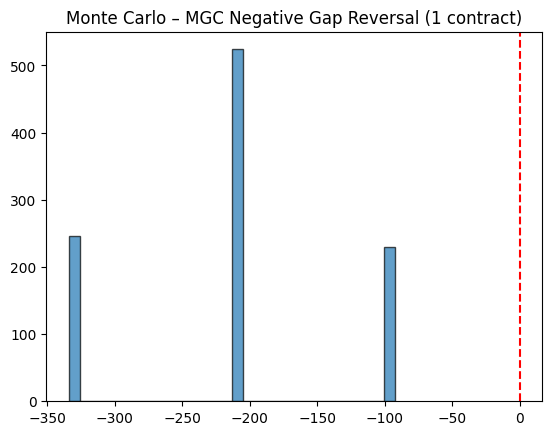

In [19]:
if df_oos_reg is not None and 'best' in locals():
    best_trades = backtest_neg_gap_reversal(df_oos_reg, best['gap_th'], int(best['hold']),
                                            best['vol_ratio'], best['atr_pct'], best['stop_mult'])
    if best_trades:
        np.random.seed(42)
        sim_pnls = []
        n_sim = 1000
        for _ in range(n_sim):
            sim = np.random.choice(best_trades, size=len(best_trades), replace=True)
            sim_pnls.append(sim.sum())
        sim_pnls = np.array(sim_pnls)
        prob_loss = (sim_pnls < 0).mean()
        print("\n=== MONTE CARLO (1000 sims, daily PnL, 1 contract) ===")
        print(f"Mean daily PnL: ${sim_pnls.mean():.2f}")
        print(f"Probability of loss: {prob_loss:.2%}")
        print(f"95% confidence interval: [${np.percentile(sim_pnls, 2.5):.2f}, ${np.percentile(sim_pnls, 97.5):.2f}]")
        plt.hist(sim_pnls, bins=30, alpha=0.7, edgecolor='black')
        plt.axvline(0, color='red', linestyle='--')
        plt.title('Monte Carlo – MGC Negative Gap Reversal (1 contract)')
        plt.show()
    else:
        print("No trades for Monte Carlo.")

## 9. Position sizing (2% risk of $25,000 = $500)

In [20]:
if df_oos_reg is not None and 'best' in locals() and best_trades:
    cum = np.cumsum(best_trades)
    running_max = np.maximum.accumulate(cum)
    drawdown = cum - running_max
    max_dd = abs(drawdown.min())
    risk_cap = 0.02 * 25000
    suggested_contracts = min(2, max(1, int(risk_cap / max_dd))) if max_dd > 0 else 2
    print("\n=== POSITION SIZING ===")
    print(f"Max drawdown (1 contract): ${max_dd:.2f}")
    print(f"Recommended contracts (2% risk): {suggested_contracts}")
    print(f"Competition max allowed: 2 → using {suggested_contracts} contracts.")
else:
    print("No drawdown data.")


=== POSITION SIZING ===
Max drawdown (1 contract): $46.00
Recommended contracts (2% risk): 2
Competition max allowed: 2 → using 2 contracts.
